### **Sampling and Quantization**

---

In [1]:
# ทำการ import โปรแกรมที่ได้มีการเขียนเองเพื่อให้ง่ายต่อการสร้างสัญญาณ

%load_ext autoreload 
%autoreload 2

import sys, os
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))

from dsp.signal_generator import make_time, create_sin, normalize_signal

**S1 (ทฤษฎี) Sampling, Nyquist และสูตรการพับความถี่ — อ่าน ThinkDSP บทที่ 2 หัวข้อ Aliasing**
  - **เขียนอะไร:** สร้าง notebook ใหม่ `notebooks/03_Sampling_and_Quantization.ipynb` แล้วเขียน markdown อธิบายด้วยคำของตัวเอง 3 คำ: sampling, Nyquist frequency, aliasing
  - **ทำนายด้วยมือ (ก่อนเขียนโค้ด):** ที่ `sr = 8000` ความถี่ 1000, 3000, 5000, 7000, 9000 Hz จะได้ยินเป็นกี่ Hz → ทำเป็นตาราง 2 คอลัมน์ (ความถี่จริง | ความถี่ที่ได้ยิน)
  - **ตอบ 2 ข้อ:** (1) Nyquist ของ `sr = 8000` และ `sr = 22050` คือเท่าไร (2) เสียงพูดในโทรศัพท์ใช้ 8000 Hz ส่วน librosa ใช้ 22050 Hz เป็นค่า default → ทำไม 22050 พอสำหรับดึง feature เพลง แต่ 8000 ไม่พอ (ใบ้: ดูช่วงความถี่ของ harmonic ในเพลง)
  - **เสร็จเมื่อ:** มีนิยาม 3 คำ, ตารางทำนาย 5 แถว และตอบครบ 2 ข้อ

  ---

  **ตอบ** : \
  **Sampling** หรือ **การสุ่มตัวอย่าง** : สัญญาณในธรรมชาติเป็นสัญญาณที่มีความต่อเนื่อง (Continuous Time Signal) แต่ว่าคอมพิวเตอร์มีข้อจำกัดไม่สามารถเก็บข้อมูลได้ จึงสร้างวิธีการเก็บข้อมูลด้วยวิธีการสุ่มตัวอย่าง (Sampling) เป็นการเก็บข้อมูลเป็นจุดในลักษณะที่ไม่ต่อเนื่องเป็นสัญญาณไม่ต่อเนื่องจากเวลา (Discrete Time Signal) \

  **Nyquist Frequency** หรือ **ความถี่ของ Nyquist** : ตามทฤษฎีของ Nyquist และ Claude Shannon บอกว่า 
  > ถ้าเราเก็บข้อมูลเป็นจุดและมีการทิ้งช่วงไว้ คอมพิวเตอร์จะสามารถสร้างสัญญาณเดิมได้ไหม ?

  คำตอบคือ ได้ โดยจะต้องให้คอมพิวเตอร์มี Sampling Rate มากกว่า 2 เท่าของความถี่สูงสุด \
  $S_r > 2f_{max}$ หรือ $f_{Nyquist}=\frac{S_r}{2}$ 

  **Aliasing** หรือ **การปลอมแปลงความถี่** : เป็นปรากฎการณ์ที่สัญญาณที่มีความถี่สูงเมื่อทำการ Sampling แล้วกลับกลายเป็นสัญญาณที่มีความถี่ต่ำ ซึ่งมีสาเหตุเกิดสัญญาณที่สนใจมีความถี่มากกว่าความถี่ของ Nyquist ในงานทางด้าน Audio Engineer ปัญหานี้จะส่งผลให้เกิด **การพับถบความถี่** ทำให้ความถี่ที่เกินจากความถี่ของ Nyquist กลับเข้ามาในช่วงของสัญญาณปลอมตัวเป็นส่วนหนึ่งกับช่วงความถี่ ซึ่งปัญหานี้ไม่สามารถแก้ไขได้ด้วย Equalizer สามารถพบได้ใน Plug-in พวก Distortion / Saturation

|ความถี่จริง|ความถี่ที่ได้ยิน|
|---|---|
|1000|1000|
|3000|3000|
|5000|4000|
|7000|4000|
|9000|4000|

1.  Nyquist Frequency ของ Sampling Rate = 8000 และ 22050 มีค่าเท่ากับเท่าไหร่ ? \
    จากสมการ    $f_{Nyquist} = \frac{S_r}{2}$ \
    จะได้        $f_{Nyquist} = \frac{8000}{2} = 4000$ Hz
    และ         $f_{Nyquist} = \frac{22050}{2} = 11025$ Hz

2. $S_r = 8000$ สามารถเก็บความถี่ได้มากที่สุดเท่ากับ 4000 Hz ซึ่งพอสำหรับเสียงพูด (300 - 3400 Hz) แต่จะตัด harmonics ของเครื่องดนตรีที่อยู่ช่วง 4 - 11 kHz ออกไป เช่น กีตาร์ ส่งผลให้ Timbre และ MFCC เพี้ยน ในขณะที่ $S_r = 22050$ สามารถเก็บความถี่ได้ถึง 11025 Hz ครอบคลุม fundamental และ harmonics แต่ก็จะไม่ครอบคลุมถึงความถี่ที่มากกว่า 11 kHz ซึ่งมีพลังงานน้อยและ Mel Scale ให้น้ำหนักน้อยอยู่แล้ว จึงพอสำหรับดึง feature และข้อมูลน้อยลงครึ่งหนึ่งเมื่อเทียบกับ 44100 

**S2 (โค้ด) เห็น aliasing ด้วยตา และพิสูจน์ด้วย `np.allclose`**
  - **สร้างอะไร:** `sr = 8000` ยาว 0.01 วินาที แล้วสร้าง sine แอมพลิจูด 1 ที่ 1000, 7000 และ 9000 Hz โดยใช้ array เวลา `t` ชุดเดียวกัน (ใช้ `create_sin` เดิมหรือเขียนใหม่ก็ได้)
  - **พล็อตที่ 1:** sine 1000 Hz กับ 9000 Hz ที่ sr = 8000 ทับกันในกราฟเดียว (ใช้ marker เป็นจุด เช่น `'o'` และ `'x'` เพื่อให้เห็นตัว sample ไม่ใช่เส้นเชื่อม) ช่วง 0–3 ms
  - **พล็อตที่ 2:** sine 9000 Hz ที่ sample ด้วย sr สูงมาก (เช่น 400000) เป็นเส้นบาง ๆ แทน "สัญญาณจริงก่อน sample" แล้ววางจุด sample ที่ sr = 8000 ของ 9000 Hz ทับลงไป ช่วง 0–1 ms
  - **เทียบด้วยโค้ด:** print `np.allclose` ของ (ก) 1000 กับ 9000 (ข) 1000 กับ 7000 (ค) 1000 กับ **ลบ**ของ 7000
  - **ตอบ 3 ข้อ:** (1) จากพล็อตที่ 2 จุด sample ของ 9000 Hz ไปตกอยู่บนรูปคลื่นความถี่เท่าไร (2) ทำไม (ข) เป็น False แต่ (ค) เป็น True (ใบ้: เขียน $\sin(2\pi \cdot 7000 \cdot n/8000)$ ใหม่โดยแยก $2\pi n$ ออกมา) (3) ผลตรงกับตาราง S1 ไหม ถ้าไม่ตรงแก้ตารางและบอกว่าพลาดตรงไหน
  - **เสร็จเมื่อ:** มีกราฟ 2 รูป (มี legend + แกน x เป็น ms), print ครบ 3 คู่ และตอบครบ 3 ข้อ

  ---

  **ตอบ**: 
  1. สังเกตจากกราฟพบว่ากราฟที่มีความถี่เท่ากับ 9000 Hz ที่ Sampling Rate = 400000 จะได้กราฟความถี่เท่ากับ 9000 Hz ในขณะที่กราฟที่มีความถี่ 9000 Hz ที่ Sampling Rate = 8000 จะได้กราฟความถี่เท่ากับ 1000 Hz 
  2. (ก) เมื่อเขียน $sin(2\pi \cdot 7000 \cdot \frac{n}{8000})$ ใหม่จะได้ $sin(2\pi n - 2\pi \cdot 1000 \cdot \frac{n}{8000})$ ซึ่ง $2\pi n$ คือการหมุนครบรอบจึงสามารถตัดทิ้งได้ เหลือแค่ $sin(- 2\pi \cdot 1000 \cdot \frac{n}{8000}) = -sin(2\pi \cdot 1000 \cdot \frac{n}{8000})$ หมายความว่า หลังการ Sample สัญญาณ 7000 Hz คือ 1000 Hz ที่มีการกลับเฟส 180° (ข) จึงเป็น False เพราะค่าแต่ละจุดมีเครื่องหมายตรงกันข้าม แต่ (ค) เป็น True เพราะเมื่อกลับหัว 7000 Hz อีกครั้งก็ได้ 1000 Hz พอดี
  3. ไม่ตรง เพราะตอนแรกมีความเข้าใจว่า ถ้าค่าความถี่ของสัญญาณเกินกว่าค่าความถี่ของ Nyquist จะแสดงแค่อัตราความถี่สูงสุดที่สัญญาณสามารถทำได้ หากแต่จะได้ความถี่ที่ยินมีค่าเท่ากับ $f_{alias}=|f - k \cdot sr|$ ซึ่งตรงกับผล `np.allclose` 
  จะสามารถแก้ไขตารางได้เป็น

  |ความถี่จริง|ความถี่ที่ได้ยิน|$f_{alias}$|
  |---|---|---|
  |1000|1000|ไม่เกิน $f_{Nyquist}$|
  |3000|3000|ไม่เกิน $f_{Nyquist}$|
  |5000|3000|$\lvert 5000 - (1 \times 8000) \rvert $|
  |7000|1000|$\lvert 7000 - (1 \times 8000) \rvert $|
  |9000|1000|$\lvert 9000 - (1 \times 8000) \rvert $|



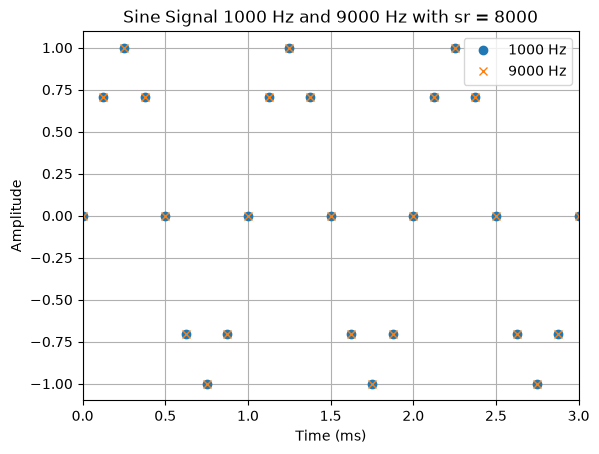

In [2]:
sr = 8000   # Sampling Rate = 8000
t = make_time(0, 0.01, sr)

sine_1000 = create_sin(1, 1000, t)  # สร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 1000
sine_7000 = create_sin(1, 7000, t)  # สร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 7000
sine_9000 = create_sin(1, 9000, t)  # สร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 9000

fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal 1000 Hz and 9000 Hz with sr = 8000")
ax.set_xlim(0, 3)   # กำหนดขอบเขตในการแสดง แสดงแค่ 0 - 3 ms
ax.grid()
ax.plot(t*1000, sine_1000, "o",label="1000 Hz")
ax.plot(t*1000, sine_9000, "x",label="9000 Hz")

ax.legend(loc="upper right")

plt.show()

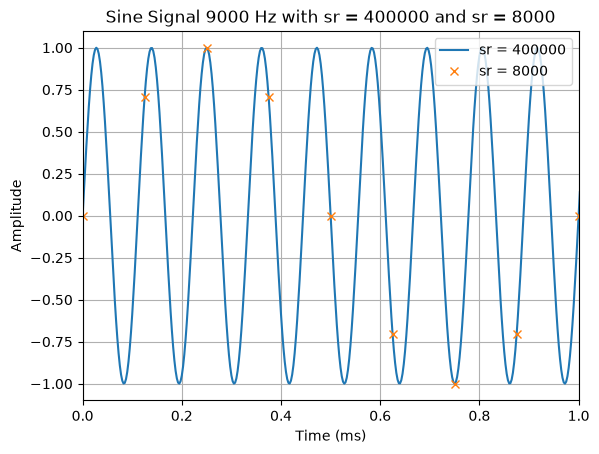

In [3]:
# Plot ด้วย Sampling Rate ที่สูงมาก  
sr_2 = 400000
t_2 = make_time(0, 0.01, sr_2)
sine_9000_sr_2 = create_sin(1, 9000, t_2)

fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal 9000 Hz with sr = 400000 and sr = 8000")
ax.set_xlim(0, 1)   # กำหนดขอบเขตในการแสดง แสดงแค่ 0 - 1 ms
ax.grid()
ax.plot(t_2*1000, sine_9000_sr_2, label="sr = 400000")
ax.plot(t*1000, sine_9000, "x",label="sr = 8000")


ax.legend(loc="upper right")

plt.show()

In [4]:
print(f'Compare 1000 Hz and 9000 Hz with np.allclose(): {np.allclose(sine_1000, sine_9000)}')
print(f'Compare 1000 Hz and 7000 Hz with np.allclose(): {np.allclose(sine_1000, sine_7000)}')
print(f'Compare 1000 Hz and -7000 Hz with np.allclose(): {np.allclose(sine_1000, -sine_7000)}')

Compare 1000 Hz and 9000 Hz with np.allclose(): True
Compare 1000 Hz and 7000 Hz with np.allclose(): False
Compare 1000 Hz and -7000 Hz with np.allclose(): True


**S3 (หู) ฟังความถี่ที่ "พับกลับ"**
  - **สร้างอะไร:** ที่ `sr = 8000` สร้าง sine ความถี่ 500, 1500, 2500, 3500, 4500, 5500, 6500, 7500 Hz ตัวละ 0.5 วินาที → `normalize_peak` ทุกตัว (จาก N3) แล้วต่อกันเป็นสัญญาณเดียวด้วย `np.concatenate` (ใบ้: list comprehension)
  - **ฟัง:** `Audio(x, rate=8000, normalize=False)` หนึ่งครั้ง โดยยังไม่ดูตาราง
  - **ตอบ 3 ข้อ:** (1) ระดับเสียงขึ้นตลอด หรือขึ้นแล้วลง และเปลี่ยนทิศที่ช่วงไหน (2) ทำตาราง 3 คอลัมน์: ความถี่ที่สร้าง | ความถี่ที่ได้ยิน (คำนวณจากสูตร S1) | หูรู้สึกตรงไหม (3) อธิบายว่าถ้าเอาเสียงที่มี harmonic สูงกว่า Nyquist ไปทำ MFCC จะเกิดปัญหาอะไรกับ feature
  - **เสร็จเมื่อ:** มีเซลล์ Audio 1 ตัว, ตาราง 8 แถว และตอบครบ 3 ข้อ


  ___ 

  **ตอบ**:
  1. จะขอตอบข้อนี้ไปพร้อมกันสองข้อ (1) และ (2) ระดับเสียงมีการขึ้นและลงโดยมีการเปลี่ยนทิศในช่วงที่ 4500 Hz \
  โดยจากข้อที่แล้วที่มีการพูดถึงเรื่องของ $f_{alias}=|f - k \cdot sr|$ โดยโอมสามารถสร้างเป็นตารางของเสียงได้ประมาณนี้

  |ความถี่ของเสียง|ความถี่ที่ได้ยิน|$f_{alias}$|
  |---|---|---|
  |500|500|ไม่เกิน $f_{Nyquist}$|
  |1500|1500|ไม่เกิน $f_{Nyquist}$|
  |2500|2500|ไม่เกิน $f_{Nyquist}$|
  |3500|3500|ไม่เกิน $f_{Nyquist}$|
  |4500|3500|$\lvert 4500 - (1 \times 8000) \rvert $|
  |5500|2500|$\lvert 5500 - (1 \times 8000) \rvert $|
  |6500|1500|$\lvert 6500 - (1 \times 8000) \rvert $|
  |7500|500|$\lvert 7500 - (1 \times 8000) \rvert $|

  หูรู้สึกค่อนข้างตรง สามารถได้ยินอย่างชัดเจนว่าในช่วงของ 4500 - 7500 Hz ลักษณะจะเหมือนกับ 3500 - 500 ตามลำดับ

  3. harmonics คือ Sine แต่ละตัว ที่มีความถี่เป็นจำนวนเท่าของความถี่ฐาน (Fundamental Frequency) ถ้าเอาเสียงที่มีความถี่ harmonics สูงกว่าความถี่ของ Nyquist จะส่งผลให้ MFCC มีความถี่แปลกปลอมเข้ามา และทำให้ MFCC มีการบอกถึง Timbre ที่ผิดไปจากความจริง และเมื่อความถี่ปลอมนี้เข้ามาผสมแล้วจะไม่สามารถใช้ Equalizer ในการแยกมันออกไปได้ 
 

In [ ]:
from IPython.display import Audio

sr_3 = 8000
t_3 = make_time(0, 0.5, sr_3)

# ต้องการสร้างสัญญาณจากความถี่ทั้งหมด 8 ตัว สร้างเป็น list เอาไว้เพื่อสร้างทีเดียว
freq = [500, 1500, 2500, 3500, 4500, 5500, 6500, 7500]
norm_signal = []    # สร้าง list เปล่า ๆ หนึ่งตัวสำหรับรอเก็บ output ที่ได้จากการ Normalization แล้ว

for f in freq:
    signal = create_sin(1, f, t_3)
    norm_signal.append(normalize_signal(signal))

concat_signal = np.concatenate(norm_signal)

Audio(concat_signal, rate=sr_3, normalize=False)

**S4 (โค้ด + หู) Quantization: bit น้อยลงเสียงพังอย่างไร**
  - **สร้างอะไร:** sine 440 Hz แอมพลิจูด 0.9, `sr = 22050`, ยาว 1 วินาที แล้วเขียนฟังก์ชัน `quantize(x, n_bits)` ที่ปัดค่าในช่วง [-1, 1] ให้เหลือ $2^{n}$ ระดับ (ใบ้: หาขนาดขั้น step ก่อน แล้วใช้ `np.round`) → สร้างเวอร์ชัน 16, 8, 4 และ 2 bit
  - **พล็อต:** ต้นฉบับ vs 4 bit vs 2 bit ช่วง 0–3 ms ในกราฟเดียว (ลองใช้ `plt.step` กับตัวที่ quantize แล้ว)
  - **วัดผล:** สำหรับแต่ละ n_bits print (ก) จำนวนค่าที่ไม่ซ้ำกันด้วย `np.unique` (ข) max abs error เทียบกับ step/2 (ค) SNR เป็น dB = $10\log_{10}\left(\sum x^2 / \sum e^2\right)$ เมื่อ $e$ = ตัวที่ quantize − ต้นฉบับ
  - **ฟัง:** 8, 4 และ 2 bit ด้วย `Audio(..., normalize=False)`
  - **ตอบ 3 ข้อ:** (1) SNR เพิ่มขึ้นประมาณกี่ dB ต่อ 1 bit และใกล้กับกฎ $6.02n + 1.76$ dB ไหม (อธิบายด้วยว่าทำไมผลของโอมต่ำกว่าสูตรเล็กน้อย ใบ้: แอมพลิจูดไม่ใช่ 1.0) (2) เสียง 2 bit ฟังแล้วเหมือนอะไร ยังได้ยินระดับเสียง 440 Hz อยู่ไหม (3) ทำไม 16 bit ถึงเพียงพอสำหรับงานของเรา (ตอบโดยอ้างตัวเลข SNR)
  - **ระวัง:** ถ้า `np.unique` ที่ 2 bit ได้ 5 ค่าแทน 4 ให้คิดว่าทำไม (ใบ้: นับระดับตั้งแต่ −1.0 ถึง +1.0 ทีละ step ดูว่าได้กี่ระดับ และ int16 จริงเก็บค่าได้ตั้งแต่เท่าไรถึงเท่าไร) แล้วแก้เอง (ใบ้: `np.clip`)
  - **เสร็จเมื่อ:** จำนวนระดับที่ไม่ซ้ำกันไม่เกิน $2^{n}$ ทุกกรณี, max error ไม่เกิน step/2, มีตาราง/print SNR ครบ 4 ค่า, เซลล์ Audio 3 ตัว และตอบครบ 3 ข้อ

  ---

  **ตอบ**:
  1. SNR เพิ่มขึ้นประมาณ 6 dB ต่อ 1 bit และค่าจะใกล้เคียงกับกฎ $6.02n+1.76$ แต่ต่ำกว่าเล็กน้อย เพราะ สูตรที่คิดที่แอมพลิจูด 1.0 แต่สัญญาณมีแอมพลิจูดเพียง 0.9 พลังงานของสัญญาณจึงลดลงเหลือ $0.9^{2}=0.81$ เท่า ขณะที่ Noise ขึ้นกับ step เท่านั้น ทำให้ SNR จึงลดลง $10log_{10}(0.81) \approx 0.9$ dB
  ส่วนที่ 2 bits ต่างจากสูตรมาก เพราะที่บริเวณยอดคลื่นสูงเกินขีดบนสุดนั่นคือ 0.5 จึงถูก clip ทำให้มี error ที่เพิ่มขึ้น
  2. เสียงมีลักษณะคล้ายแตรของรถยนต์ และมีความเป็นเสียงของ 440 Hz อยู่เป็นลักษณะของเสียงที่คล้ายกัน แต่แตกต่างกันตรง Timbre ของเสียงให้ความรู้สึกที่บาดหู
  3. เพราะอ้างอิงจาก SNR ที่เมื่อมีค่ามากค่าความเพี้ยนระหว่างสัญญาณจริงกับสัญญาณ Noise จะลดลงซึ่งมีค่ามากถึงประมาณ 97 dB จึงเพียงพอต่อการใช้งาน

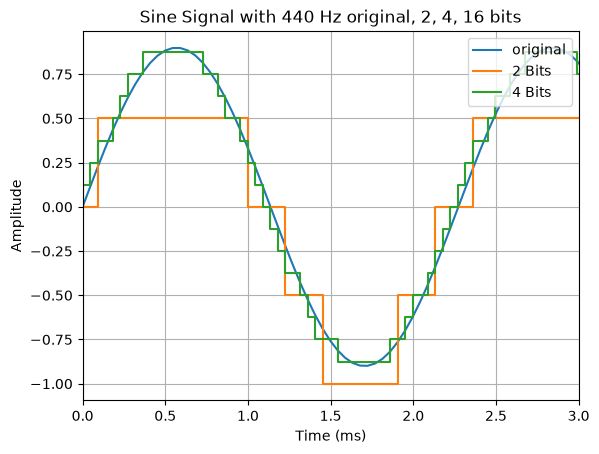

Amount of unique numbers in 2 bits : 4
unique numbers in 2 bits : [-1.  -0.5 -0.   0.5]
------------------------------------------------------
Amount of unique numbers in 4 bits : 15
unique numbers in 4 bits : [-0.875 -0.75  -0.625 -0.5   -0.375 -0.25  -0.125  0.     0.125  0.25
  0.375  0.5    0.625  0.75   0.875]
------------------------------------------------------
Amount of unique numbers in 8 bits : 231
unique numbers in 8 bits : [-0.8984375 -0.890625  -0.8828125 -0.875     -0.8671875 -0.859375
 -0.8515625 -0.84375   -0.8359375 -0.828125  -0.8203125 -0.8125
 -0.8046875 -0.796875  -0.7890625 -0.78125   -0.7734375 -0.765625
 -0.7578125 -0.75      -0.7421875 -0.734375  -0.7265625 -0.71875
 -0.7109375 -0.703125  -0.6953125 -0.6875    -0.6796875 -0.671875
 -0.6640625 -0.65625   -0.6484375 -0.640625  -0.6328125 -0.625
 -0.6171875 -0.609375  -0.6015625 -0.59375   -0.5859375 -0.578125
 -0.5703125 -0.5625    -0.5546875 -0.546875  -0.5390625 -0.53125
 -0.5234375 -0.515625  -0.5078125 -0.5 

In [6]:
sr_4 = 22050
t_quan = make_time(0, 1, sr_4)
sine_440_2 = create_sin(0.9, 440, t_quan)

# สร้างฟังก์ชันสำหรับการทำ Quantization
def quantize(signal, n_bits):
    step = 2 / (2 ** n_bits)   # หาจำนวนขั้นที่ต้องการแบ่งก่อนว่าแต่ละขั้นมีค่าเท่าไหร่
    position = signal/step          # หาตำแหน่งของสัญญาณว่าจะไปอยู่ที่ไหนของการทำ Quantize
    rounded = np.round(position)
    return np.clip(rounded * step, -1, 1-step)

sine_440_16bits = quantize(sine_440_2, 16)  # สร้างสัญญาณ Sine ความถี่ 440 Hz ที่มีการ Quantize จำนวน 16 Bits
sine_440_8bits = quantize(sine_440_2, 8)    # สร้างสัญญาณ Sine ความถี่ 440 Hz ที่มีการ Quantize จำนวน 8 Bits
sine_440_4bits = quantize(sine_440_2, 4)    # สร้างสัญญาณ Sine ความถี่ 440 Hz ที่มีการ Quantize จำนวน 4 Bits
sine_440_2bits = quantize(sine_440_2, 2)    # สร้างสัญญาณ Sine ความถี่ 440 Hz ที่มีการ Quantize จำนวน 2 Bits

fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal with 440 Hz original, 2, 4, 16 bits")
ax.grid()
ax.set_xlim(0, 3)
ax.plot(t_quan*1000, sine_440_2, label="original")
plt.step(t_quan*1000, sine_440_2bits, label="2 Bits")
plt.step(t_quan*1000, sine_440_4bits, label="4 Bits")

ax.legend(loc="upper right")

plt.show()

print(f"Amount of unique numbers in 2 bits : {(len(np.unique(sine_440_2bits)))}")
print(f"unique numbers in 2 bits : {(np.unique(sine_440_2bits))}")
print("------------------------------------------------------")
print(f"Amount of unique numbers in 4 bits : {(len(np.unique(sine_440_4bits)))}")
print(f"unique numbers in 4 bits : {(np.unique(sine_440_4bits))}")
print("------------------------------------------------------")
print(f"Amount of unique numbers in 8 bits : {(len(np.unique(sine_440_8bits)))}")
print(f"unique numbers in 8 bits : {(np.unique(sine_440_8bits))}")
print("------------------------------------------------------")
print(f"Amount of unique numbers in 16 bits : {(len(np.unique(sine_440_16bits)))}")
print(f"unique numbers in 16 bits : {(np.unique(sine_440_16bits))}")
print("------------------------------------------------------")

In [7]:
for n in [2, 4, 8, 16]:
    q = quantize(sine_440_2, n)
    e = q - sine_440_2  # error
    step = 2/(2**n)
    max_e = np.max(np.abs(e))
    snr = 10 * np.log10(np.sum(sine_440_2**2)/np.sum(e**2))
    print(f"{n} bit | levels {len(np.unique(q))} | max error {max_e:.6f} | step/2 {step/2:.6f} | SNR {snr:.2f} dB")



2 bit | levels 4 | max error 0.400000 | step/2 0.250000 | SNR 9.92 dB
4 bit | levels 15 | max error 0.062375 | step/2 0.062500 | SNR 25.51 dB
8 bit | levels 231 | max error 0.003903 | step/2 0.003906 | SNR 49.15 dB
16 bit | levels 2189 | max error 0.000015 | step/2 0.000015 | SNR 97.43 dB


In [ ]:
Audio(sine_440_2bits, rate=sr_4, normalize=False)

In [ ]:
Audio(sine_440_4bits, rate=sr_4, normalize=False)

In [ ]:
Audio(sine_440_8bits, rate=sr_4, normalize=False)

In [ ]:
Audio(sine_440_16bits, rate=sr_4, normalize=False)